# Compound heat–drought stress over India: mid-evaluation analysis

**EVS Project, IIIT Hyderabad.** Arnav Deshmukh, Ayush Brajesh Roy, Saksham Chitkara, Gracy Garg, Rudra Choudhary

**Question:** does simultaneous heat and drought cause more ecosystem stress than either alone?

This notebook contains every analysis and every figure in our mid-evaluation slides:

| Section | Slide(s) |
|---|---|
| 1. Data and study area | Why India?, Step 1: data |
| 2. Sorting months into four boxes | Step 2: anomalies, Step 3: four boxes |
| 3. Where compound months happen | Where compound months happen |
| 4. H1: is vegetation hit harder in compound months? | H1 slides |
| 5. H2: is the combination worse than the sum? | H2 slides, response surface |
| 6. Summary | Observations so far |

Hypotheses H3 (recovery) and H4 (land cover and region) are planned for the final evaluation and are not part of this notebook.

**Before running:** download the data and build the cube with the scripts (see `README.md`):
`scripts/00_check_gee.py` → `scripts/01_fetch.py` → `scripts/02_build_cube.py`.
This notebook reads `data/processed/cube.nc`. Figures are saved to `figures/` and tables to `results/`.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from chd import config as cfg
from chd import impacts
from chd import plotting as plot

pd.set_option("display.precision", 3)


ds = xr.open_dataset(cfg.CUBE_PATH)
df = impacts.cube_to_long_table(ds)   # one row per growing-season cell-month inside India
print(f"Cube: {dict(ds.sizes)}")
print(f"Growing-season cell-months used in the statistics: {len(df):,}")

Cube: {'time': 264, 'lat': 126, 'lon': 120}
Growing-season cell-months used in the statistics: 824,598


In [2]:
def fmt(est, lo, hi):
    """'-0.13 [-0.24, -0.01]' style, as on the slides."""
    return f"{est:+.2f} [{lo:+.2f}, {hi:+.2f}]"

## 1. Data and study area

All data come from Google Earth Engine, aggregated to one 0.25° grid (≈27 km), monthly:

| Dataset | What we use | Period | Role |
|---|---|---|---|
| ERA5-Land | daily max temperature; soil moisture 0–100 cm; VPD | 1991–2024 | defines "hot"; mechanism |
| SPEI v2.11 | SPEI-3 (rain minus evaporative demand) | 1991–2024 | defines "dry" |
| CHIRPS v2 | rainfall → SPI-3 | 1991–2024 | temperature-free drought check |
| MODIS MOD17A2H | GPP (photosynthesis) | 2001–2022 | main response |
| MODIS MOD13A3 | NDVI (greenness), quality-masked | 2001–2022 | second response |
| ESA WorldCover | land-cover fractions | 2021 | vegetation mask; land cover map |

Grid cells inside India: 4,481
Cells where cropland is the dominant cover: 59.5%


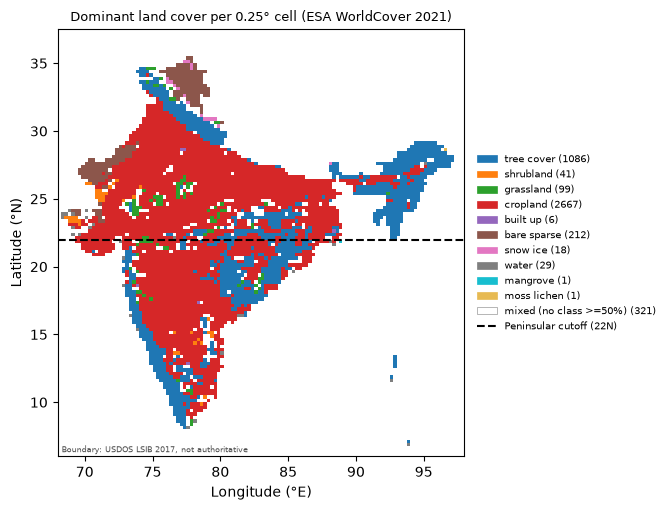

In [3]:
india = ds["is_india"].values
frac_cols = [c for c in ds.data_vars if c.startswith("frac_")]
fracs = np.nan_to_num(np.stack([ds[c].values for c in frac_cols]))
dominant = np.array(frac_cols)[fracs.argmax(axis=0)]
pure = fracs.max(axis=0) >= cfg.THRESH.landcover_purity
crop_share = (india & pure & (dominant == "frac_cropland")).sum() / india.sum()

print(f"Grid cells inside India: {int(india.sum()):,}")
print(f"Cells where cropland is the dominant cover: {100 * crop_share:.1f}%")
plot.plot_study_area(ds);

## 2. Sorting every grid-month into four boxes

Each value is first turned into a **z-score** for its own grid cell and calendar month
(`z = (value − normal for this cell in this month) / typical year-to-year spread`), so May is compared
with other Mays and a forest with itself.

- **Temperature:** baseline 1991–2020, *not* detrended (long-term warming counts as heat).
- **GPP, NDVI:** linear trend removed first (long-term greening is not an anomaly).
- **Only growing-season months count:** cell inside India, ≥50% vegetated, and GPP in that month is normally ≥30% of its peak.

Then each month goes into one box: **hot** = Tmax z ≥ 1, **dry** = SPEI-3 ≤ −1.
SPEI's demand term depends on temperature, so everything is repeated with **SPI-3** (rainfall only).

In [4]:
counts = impacts.category_counts(df)
counts.to_csv(cfg.RESULTS / "category_counts.csv", index=False)
counts.style.format({"n": "{:,}", "pct": "{:.1f}%"}).hide(axis="index")

category,n,pct
normal,"573,543",69.6%
hot_only,"79,717",9.7%
dry_only,"109,073",13.2%
compound,"62,265",7.6%


## 3. Where compound months happen

Compound share of growing-season cell-months: 7.6%
Compound cell-months north / south of 22N: 39,784 / 22,481


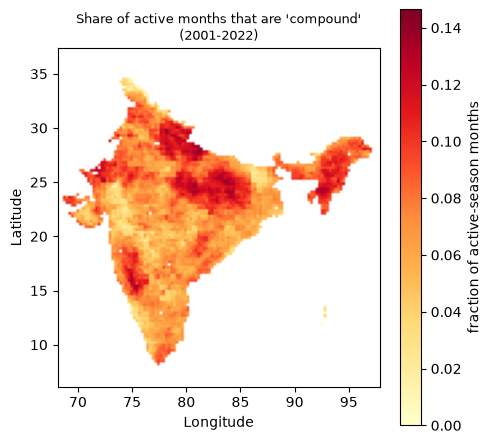

In [5]:
freq = impacts.compound_frequency(ds)
plot.plot_compound_frequency(freq, ds["lat"].values, ds["lon"].values);

comp = df[df["category"] == "compound"]
print(f"Compound share of growing-season cell-months: {100 * len(comp) / len(df):.1f}%")
# sample-size check only: enough compound months both north and south of 22N
print(f"Compound cell-months north / south of {cfg.PENINSULAR_LAT_MAX:.0f}N: "
      f"{int((comp['lat'] > cfg.PENINSULAR_LAT_MAX).sum()):,} / {int((comp['lat'] <= cfg.PENINSULAR_LAT_MAX).sum()):,}")

## 4. H1: is vegetation hit harder in compound months?

Mean GPP z and NDVI z in each box. 95% confidence intervals come from a **year-block bootstrap**:
whole years are resampled 1,000 times, because cell-months from the same year are not independent.
A result is significant when its interval excludes zero.

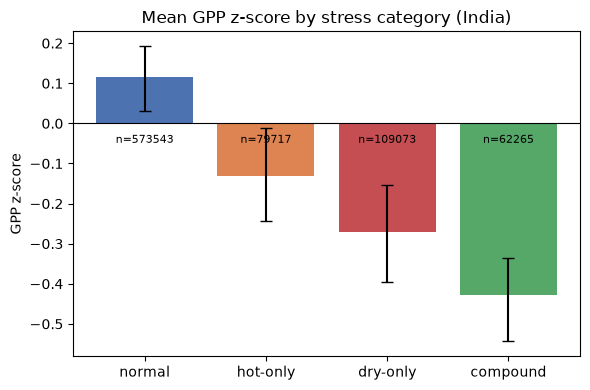

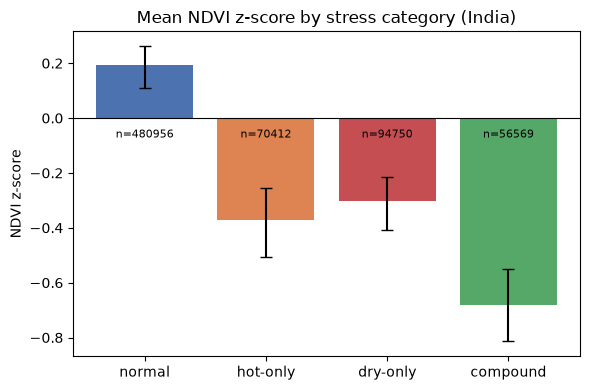

,normal,hot_only,dry_only,compound
Mean z [95% CI],,,,
GPP,+0.12,"-0.13 [-0.24, -0.01]","-0.27 [-0.40, -0.15]","-0.43 [-0.54, -0.33]"
NDVI,+0.19,"-0.37 [-0.50, -0.26]","-0.30 [-0.41, -0.21]","-0.68 [-0.81, -0.55]"


In [6]:
composites, contrasts = {}, {}
for v, label in [("gpp_z", "GPP z-score"), ("ndvi_z", "NDVI z-score")]:
    composites[v] = impacts.category_composites(df, v)
    composites[v].to_csv(cfg.RESULTS / f"composite_{v}_overall.csv", index=False)
    contrasts[v] = impacts.category_contrasts(df, v)
    contrasts[v].to_csv(cfg.RESULTS / f"contrasts_{v}_overall.csv", index=False)
    plot.plot_category_composite(composites[v], label, f"Mean {label} by stress category (India)",
                                 f"composite_{v}_overall")
plt.show()

table = pd.DataFrame({
    v.split("_")[0].upper(): {r.category: (f"{r.mean:+.2f}" if r.category == "normal" else fmt(r.mean, r.ci_low, r.ci_high))
                              for r in composites[v].itertuples()}
    for v in ("gpp_z", "ndvi_z")}).T
table.index.name = "Mean z [95% CI]"
table

In [7]:
rob = impacts.robustness_spei_vs_spi(df)
rob.to_csv(cfg.RESULTS / "robustness_spei_vs_spi.csv", index=False)

rows = []
for v in ("gpp_z", "ndvi_z"):
    c = contrasts[v].iloc[0]
    spi = rob[(rob.response == v) & (rob.drought_index == "SPI-3")].iloc[0]
    rows.append({"response": v.split("_")[0].upper(),
                 "compound − dry-only": fmt(c.compound_minus_dry, c.compound_minus_dry_ci_low, c.compound_minus_dry_ci_high),
                 "compound − hot-only": fmt(c.compound_minus_hot, c.compound_minus_hot_ci_low, c.compound_minus_hot_ci_high),
                 "compound − dry-only (SPI-3)": fmt(spi.compound_minus_dry, spi.compound_minus_dry_ci_low, spi.compound_minus_dry_ci_high)})
pd.DataFrame(rows).set_index("response")

,compound − dry-only,compound − hot-only,compound − dry-only (SPI-3)
response,,,
GPP,"-0.16 [-0.26, -0.04]","-0.30 [-0.40, -0.21]","-0.26 [-0.37, -0.13]"
NDVI,"-0.38 [-0.49, -0.28]","-0.31 [-0.43, -0.21]","-0.48 [-0.61, -0.35]"


All three stress types lower GPP and NDVI compared with normal months, and **compound months are
significantly worse than either single stress**, with both drought indices.

**Why?** Compound months combine the driest soils *and* the thirstiest air:

In [8]:
mech = impacts.mechanism_check(df)
mech.to_csv(cfg.RESULTS / "mechanism_check.csv", index=False)
mech.rename(columns={"sm_z": "root-zone soil moisture z", "vpd_z": "air dryness (VPD) z"}).set_index("category").T.round(2)

category,normal,hot_only,dry_only,compound
root-zone soil moisture z,0.29,-0.75,-0.38,-1.04
air dryness (VPD) z,-0.38,1.11,0.18,1.43


**H1 supported.**

## 5. H2: is the combination worse than the sum?

Each effect is measured relative to normal months (Δ = category mean − normal mean):

**Amplification = Δcompound − (Δhot + Δdry)**: < 0 synergy, ≈ 0 additive, > 0 sub-additive.

All contrasts come from one *joint* bootstrap, so every one gets a valid confidence interval.

,SPEI-3,SPI-3
Amplification [95% CI],,
GPP,"+0.09 [-0.03, +0.21]","-0.00 [-0.12, +0.13]"
NDVI,"+0.18 [+0.06, +0.30]","+0.06 [-0.05, +0.18]"


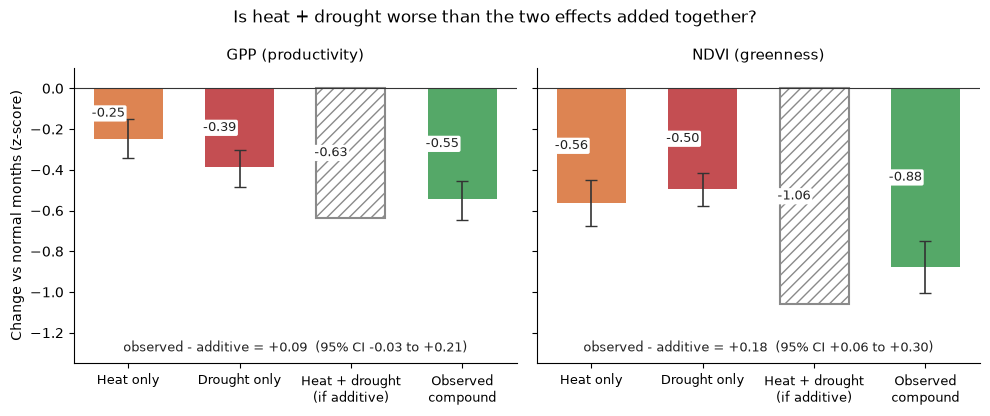

In [9]:
plot.plot_additivity(contrasts);

ai = pd.DataFrame({
    idx: {r.response.split("_")[0].upper(): fmt(r.amplification_index, r.amplification_index_ci_low, r.amplification_index_ci_high)
          for r in rob[rob.drought_index == idx].itertuples()}
    for idx in ("SPEI-3", "SPI-3")})
ai.index.name = "Amplification [95% CI]"
ai

**No synergy:** the amplification is never significantly negative. Heat and drought damages roughly
**add up**: compound months are worse than either alone, but not worse than both together.
With SPEI-3, NDVI is even slightly *less* than additive, but this disappears with SPI-3, so
**the drought definition matters**.

### Response surface (a check without boxes)

Every growing-season month placed by its heat (x, Tmax z) and water balance (y, SPEI-3, lower = drier).
Each square is the average GPP z of all months in that 0.5 × 0.5 range (grey = fewer than 30 months).
Dashed lines are our cut-offs, so the bottom-right corner is the compound box.

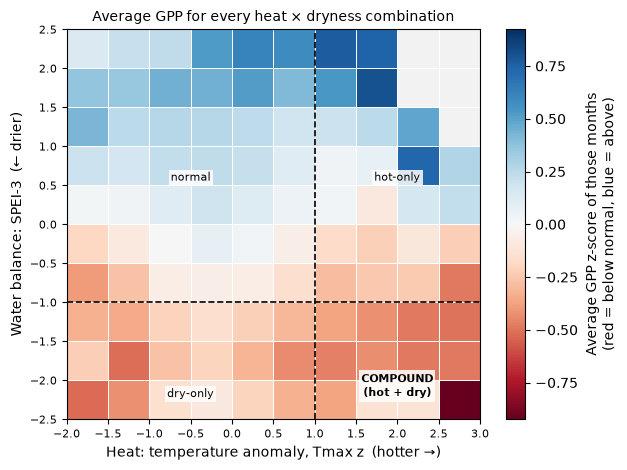

Mean GPP z per SPEI-3 row (wettest first):
 spei_low  mean_gpp_z
      2.0        0.48
      1.5        0.48
      1.0        0.28
      0.5        0.23
      0.0        0.09
     -0.5       -0.10
     -1.0       -0.23
     -1.5       -0.34
     -2.0       -0.38
     -2.5       -0.33

Worst square: Tmax z (2.5, 3.0], SPEI-3 (-2.5, -2.0]: -0.92 (n=670)
Hot (Tmax z >= 1) but wet (SPEI-3 >= 0) months: mean GPP z +0.09


In [10]:
surf = impacts.response_surface(df, "gpp_z")
surf.to_csv(cfg.RESULTS / "response_surface_gpp.csv", index=False)
plot.plot_response_surface(surf);
plt.show()

rows = impacts.surface_row_means(surf)
print("Mean GPP z per SPEI-3 row (wettest first):")
print(rows.round(2).to_string(index=False))

shown = surf.dropna(subset=["mean"])
worst = shown.sort_values("mean").iloc[0]
print(f"\nWorst square: Tmax z {worst.tz_bin}, SPEI-3 {worst.spei_bin}: {worst['mean']:.2f} (n={int(worst.n)})")
hot_wet = shown[(shown.tz_bin.map(lambda i: i.left) >= 1) & (shown.spei_bin.map(lambda i: i.left) >= 0)]
print(f"Hot (Tmax z >= 1) but wet (SPEI-3 >= 0) months: mean GPP z {np.average(hot_wet['mean'], weights=hot_wet['n']):+.2f}")

GPP falls as it gets drier (about +0.5 in the wettest rows, −0.35 in the driest). The worst square is the
hottest + driest corner (−0.92), while hot but wet months are not below normal on average.
Dryness is the main driver and heat adds to it, consistent with additive effects.

**H2 not supported** (for average productivity, India-wide).

## 6. Summary (as on the "Observations so far" slide)

- **H1 supported.** Compound heat–drought months reduce GPP and NDVI significantly more than heat alone or drought alone, for both drought indices.
- **H2 not supported.** The compound effect is about the *sum* of the heat and drought effects, not more.
- **Mechanism.** Compound months have the driest soils and the thirstiest air at the same time.
- **Drought definition matters.** SPEI vs SPI changes the H2 details. Hot-only months also have dry soils (soil moisture z = −0.75), which rainfall-based indices miss.
- **Caveats.** MOD17 GPP is partly modelled (it uses air dryness and temperature, and has no soil-moisture input). NDVI is from the same satellite. Monthly 0.25° data blur short heatwaves.